In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report,ConfusionMatrixDisplay,RocCurveDisplay)
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("most_used_beauty_cosmetics_products_extended.csv")
print(df.head())
print("Shape:", df.shape)
print(df.columns.tolist())

       Product_Name              Brand        Category Usage_Frequency  \
0   Ultra Face Mask     Drunk Elephant           Blush          Weekly   
1    Ultra Lipstick      Laura Mercier  Makeup Remover      Occasional   
2       Ultra Serum     Natasha Denona     Highlighter           Daily   
3      Divine Serum        Ilia Beauty       Face Mask      Occasional   
4  Super Foundation  Charlotte Tilbury     Highlighter      Occasional   

   Price_USD  Rating  Number_of_Reviews Product_Size  Skin_Type Gender_Target  \
0      67.85     1.4                686         30ml  Sensitive        Female   
1     116.43     4.2               5483        250ml        Dry        Unisex   
2      90.84     1.6               5039        100ml  Sensitive          Male   
3      55.17     3.2               6202        250ml     Normal          Male   
4     140.56     1.7                297        100ml       Oily        Female   

  Packaging_Type Main_Ingredient  Cruelty_Free Country_of_Origin  
0

In [3]:
df.info()
print("\nStatistical Summary:")
print(df.describe())
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Records:")
print(df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Product_Name       15000 non-null  str    
 1   Brand              15000 non-null  str    
 2   Category           15000 non-null  str    
 3   Usage_Frequency    15000 non-null  str    
 4   Price_USD          15000 non-null  float64
 5   Rating             15000 non-null  float64
 6   Number_of_Reviews  15000 non-null  int64  
 7   Product_Size       15000 non-null  str    
 8   Skin_Type          15000 non-null  str    
 9   Gender_Target      15000 non-null  str    
 10  Packaging_Type     15000 non-null  str    
 11  Main_Ingredient    15000 non-null  str    
 12  Cruelty_Free       15000 non-null  bool   
 13  Country_of_Origin  15000 non-null  str    
dtypes: bool(1), float64(2), int64(1), str(10)
memory usage: 1.5 MB

Statistical Summary:
          Price_USD        Rating  Number_of

In [4]:
df = df.dropna(subset=["Rating"]).copy()
df["High_Rating"] = np.where(df["Rating"] >= 4.0, 1, 0)
print(df["High_Rating"].value_counts())
print("\nTarget distribution:")
print(df["High_Rating"].value_counts(normalize=True) * 100)

High_Rating
0    10930
1     4070
Name: count, dtype: int64

Target distribution:
High_Rating
0    72.866667
1    27.133333
Name: proportion, dtype: float64


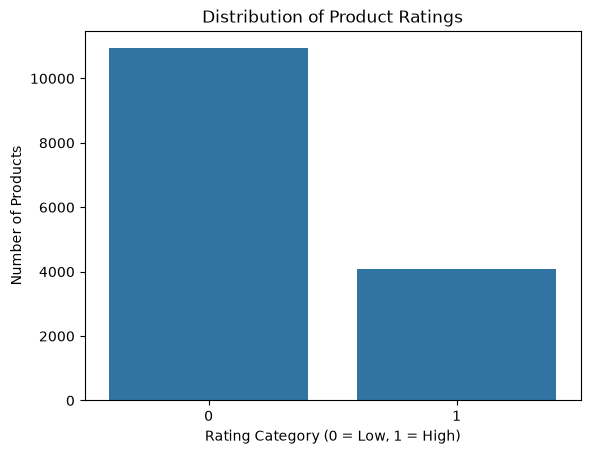

In [5]:
sns.countplot(data=df, x="High_Rating")
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating Category (0 = Low, 1 = High)")
plt.ylabel("Number of Products")
plt.show()

In [6]:
y = df["High_Rating"]
X = df.drop(columns=["Rating", "High_Rating"],errors="ignore")
X = X.drop(columns=["Product_ID", "ID"],errors="ignore")
X = X.dropna(axis=1, how="all")
print(X.columns.tolist())
print("\nTarget:")
print(y.head())

['Product_Name', 'Brand', 'Category', 'Usage_Frequency', 'Price_USD', 'Number_of_Reviews', 'Product_Size', 'Skin_Type', 'Gender_Target', 'Packaging_Type', 'Main_Ingredient', 'Cruelty_Free', 'Country_of_Origin']

Target:
0    0
1    1
2    0
3    0
4    0
Name: High_Rating, dtype: int64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (12000, 13)
Testing data: (3000, 13)


In [8]:
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns
preprocessor = ColumnTransformer(transformers=[("num", StandardScaler(), numeric_features),("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])
print("Numerical features:", list(numeric_features))
print("Categorical features:", list(categorical_features))

Numerical features: ['Price_USD', 'Number_of_Reviews']
Categorical features: ['Product_Name', 'Brand', 'Category', 'Usage_Frequency', 'Product_Size', 'Skin_Type', 'Gender_Target', 'Packaging_Type', 'Main_Ingredient', 'Cruelty_Free', 'Country_of_Origin']


In [10]:
models = {"Logistic Regression": LogisticRegression(max_iter=1000,random_state=42),"Decision Tree": DecisionTreeClassifier(max_depth=5,random_state=42),"Random Forest": RandomForestClassifier(n_estimators=200,max_depth=10,random_state=42)}
trained_models = {}
for name, model in models.items():
    pipeline = Pipeline([("preprocessing", preprocessor),("model", model)])
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [11]:
results = []
for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results.append({"Model": name,"Accuracy": accuracy_score(y_test, y_pred),"Precision": precision_score(y_test, y_pred, zero_division=0),"Recall": recall_score(y_test, y_pred, zero_division=0),"F1 Score": f1_score(y_test, y_pred, zero_division=0),"ROC-AUC": roc_auc_score(y_test,y_prob)})
results_df = pd.DataFrame(results)
print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.7280     0.0000  0.0000    0.0000   0.5047
1        Decision Tree    0.7270     0.3913  0.0111    0.0215   0.5058
2        Random Forest    0.7287     0.0000  0.0000    0.0000   0.5140


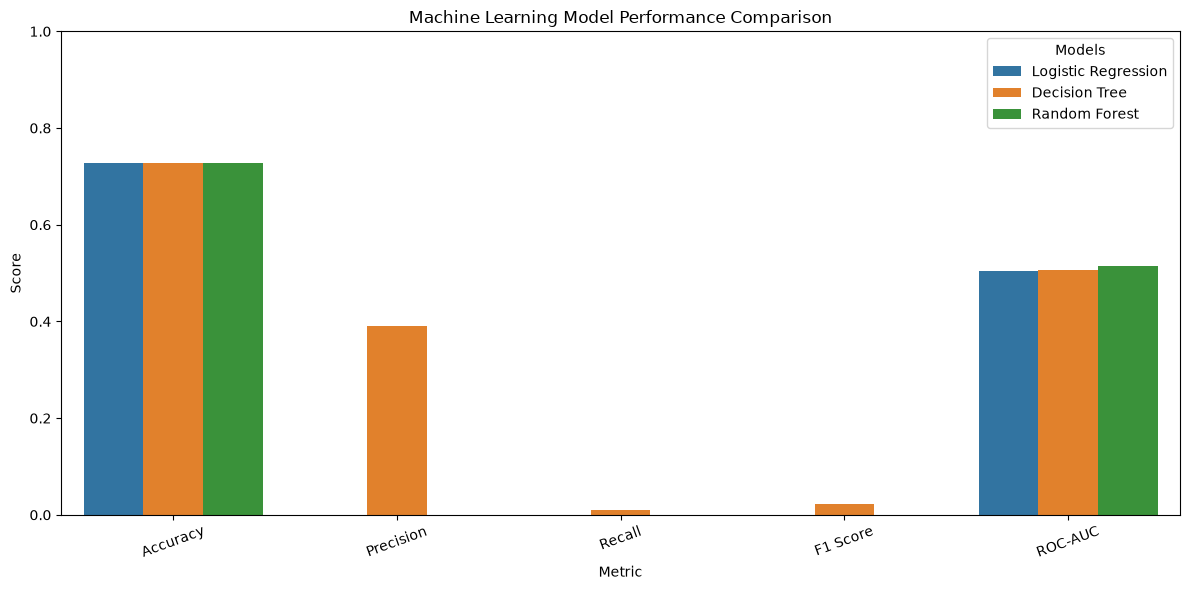

In [12]:
results_melted = results_df.melt(id_vars="Model",var_name="Metric",value_name="Score")
plt.figure(figsize=(12, 6))
sns.barplot(data=results_melted,x="Metric",y="Score",hue="Model")
plt.title("Machine Learning Model Performance Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title="Models")
plt.tight_layout()
plt.show()

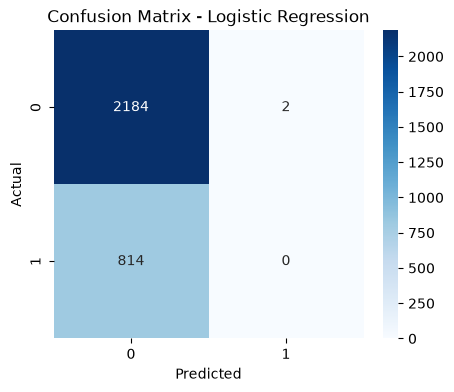

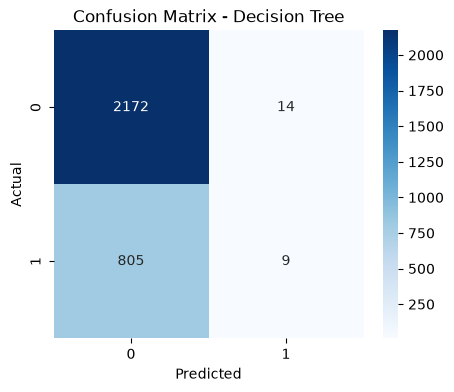

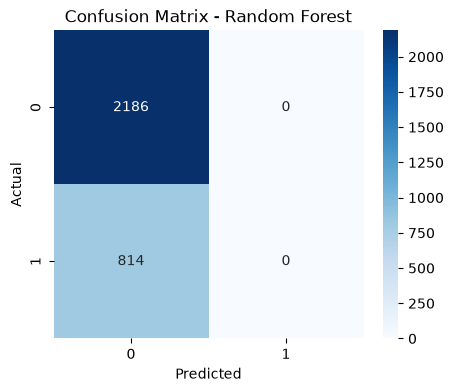

In [13]:
for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

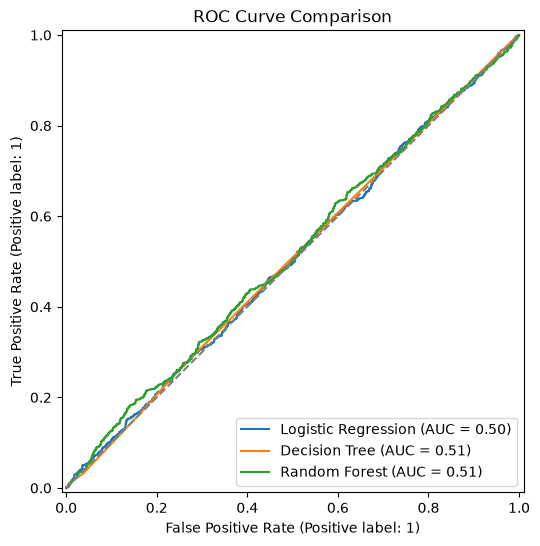

In [14]:
plt.figure(figsize=(8, 6))
for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test,y_prob,name=name,ax=plt.gca())
plt.title("ROC Curve Comparison")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.show()

In [15]:
cv_results = []
for name, model in trained_models.items():
    scores = cross_val_score(model,X_train,y_train,cv=5,scoring="f1")
    cv_results.append({"Model": name,"Mean F1 Score": scores.mean(),"Standard Deviation": scores.std()})
cv_df = pd.DataFrame(cv_results)
print(cv_df.round(4))

                 Model  Mean F1 Score  Standard Deviation
0  Logistic Regression         0.0043              0.0015
1        Decision Tree         0.0247              0.0111
2        Random Forest         0.0000              0.0000


                                   Feature  Importance
1                   num__Number_of_Reviews    0.080353
0                           num__Price_USD    0.064505
215       cat__Main_Ingredient_Shea Butter    0.011574
188        cat__Usage_Frequency_Occasional    0.010883
203              cat__Gender_Target_Unisex    0.010597
202                cat__Gender_Target_Male    0.010567
63   cat__Product_Name_Perfect Highlighter    0.010485
168                  cat__Category_Contour    0.010303
190                cat__Product_Size_100ml    0.010234
204             cat__Packaging_Type_Bottle    0.010142
199                    cat__Skin_Type_Oily    0.010137
200               cat__Skin_Type_Sensitive    0.009858
187           cat__Usage_Frequency_Monthly    0.009833
198                  cat__Skin_Type_Normal    0.009819
208              cat__Packaging_Type_Stick    0.009695


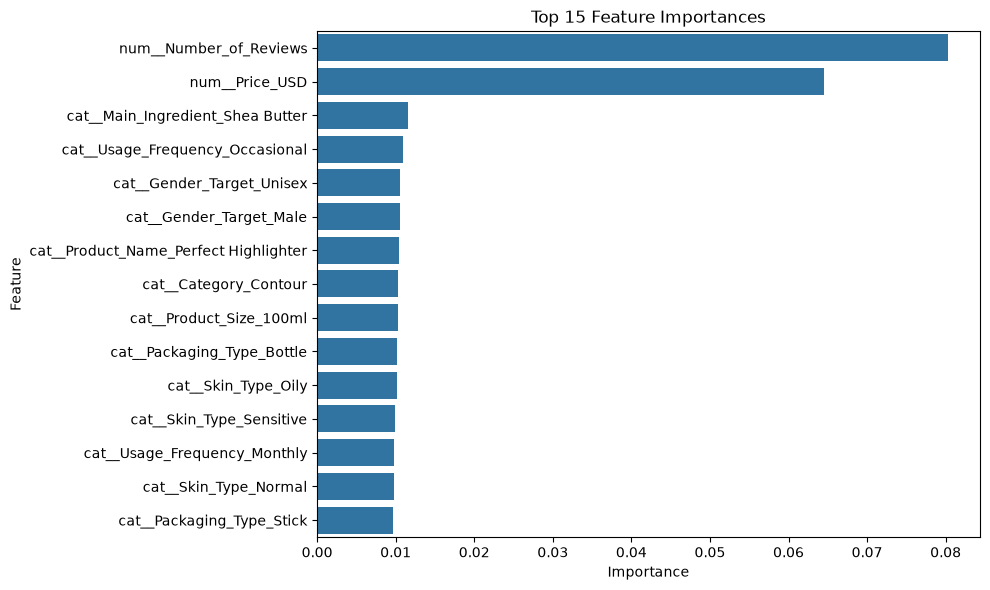

In [16]:
rf_model = trained_models["Random Forest"]
feature_names = rf_model.named_steps["preprocessing"].get_feature_names_out()
importances = rf_model.named_steps["model"].feature_importances_
importance_df = pd.DataFrame({"Feature": feature_names,"Importance": importances})
importance_df = importance_df.sort_values(by="Importance",ascending=False)
print(importance_df.head(15))
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(15),x="Importance",y="Feature")
plt.title("Top 15 Feature Importances")
plt.tight_layout()
plt.show()

In [17]:
best_model_name = results_df.loc[results_df["F1 Score"].idxmax(), "Model"]
print("Best Performing Model:", best_model_name)
best_model = trained_models[best_model_name]
y_pred = best_model.predict(X_test)
print("\nClassification Report:\n")
print(classification_report(y_test,y_pred,target_names=["Low Rating", "High Rating"],zero_division=0))

Best Performing Model: Decision Tree

Classification Report:

              precision    recall  f1-score   support

  Low Rating       0.73      0.99      0.84      2186
 High Rating       0.39      0.01      0.02       814

    accuracy                           0.73      3000
   macro avg       0.56      0.50      0.43      3000
weighted avg       0.64      0.73      0.62      3000



In [18]:
results_df.to_csv("week6_model_evaluation.csv",index=False)
cv_df.to_csv("week6_cross_validation.csv",index=False)
importance_df.to_csv("week6_feature_importance.csv",index=False)
print("Evaluation reports saved successfully!")

Evaluation reports saved successfully!
